# Mouse E13 embryo: Fig. 4d-f

The saved joint embedding leads to the fixed spatial partition displayed in **Fig. 4d**. Follow the barcode alignment from embedding to tissue coordinates and final labels.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/03_Mouse_E13/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "03_Mouse_E13"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved MELON embedding and labels

Align `03_embeddings/MELON.csv` with the MELON column in `04_clusters/final_clusters.csv` by barcode.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 2187
display(pd.DataFrame({"spots": [len(labels)], "embedding_dimensions": [embedding.shape[1]],
                       "MELON_domains": [labels.MELON.nunique()]}))

,spots,embedding_dimensions,MELON_domains
0,2187,128,14


## 2. Display the MELON spatial domains

Each dot is one saved spot, colored by its existing MELON domain label.

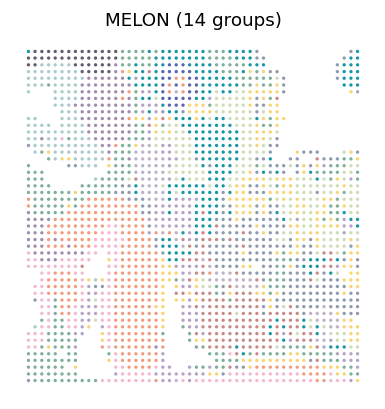

In [3]:
show(spatial_panels(labels, ["MELON"], ncols=1))

## 3. Read the stored t-SNE — Supplementary Fig. 8e

The supplementary t-SNE has its own saved source embedding and domain column. Read both from `03_embeddings/supplementary_tsne/`; do not substitute the main-comparison embedding or fit t-SNE again.

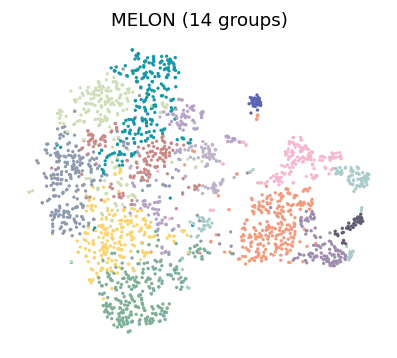

In [4]:
tsne = read_indexed(DATA / "03_embeddings/supplementary_tsne/saved_tsne.csv")
tsne_source = read_indexed(DATA / "03_embeddings/supplementary_tsne/source_embedding.csv")
tsne_source = align_embedding(tsne_source, tsne)
show(spatial_panels(tsne, ["melon_domain"], x="TSNE1", y="TSNE2", ncols=1, invert_y=False))

## 4. Keep the cis-pair branch separate

Fig. 4f uses MACS3 genomic peaks and a separately archived decoder embedding. It is distinct from the main clustering embedding. The saved decoder settings record a 24-factor, binary-ATAC model.

In [5]:
pair_embedding = read_indexed(DATA / "03_embeddings/decoder_MACS3/MELON.csv")
pair_settings = json.loads((DATA / "02_model_inputs/decoder_MACS3/saved_settings.json").read_text())
display(pd.DataFrame([{"spots": len(pair_embedding), "dimensions": pair_embedding.shape[1],
                       "factors": pair_settings["n_factors"], "ATAC_mode": pair_settings["atac_mode"]}]))

,spots,dimensions,factors,ATAC_mode
0,2187,128,24,binary


Source files and any additional downstream inputs are listed in [figure sources](../FIGURE_SOURCES.md).